# SGD NEER: trade the constituents behind an index deviation

The existing index still determines entry and exit. Each selected SGD cross keeps its correctly accumulated USDSGD hedge. Constituents and sizes are frozen during the trade.

For the 24h EWMA / 1.5z trigger, the **risk-matched aligned subset** reduced 2024–2025 spread costs by **33.5%**, with net Sharpe **0.991 versus 0.907**. The Sharpe improvement is statistically uncertain and does not hold in every earlier period. Forward points remain excluded. [Full written methods and results](sgd_neer_subset_report.md).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

research = next(p/s for p in [Path.cwd(), *Path.cwd().parents]
                for s in ['', 'src/systematic_trading/research/sgd_neer_codex']
                if (p/s/'sgd_neer_results/subset/comparison.csv').exists())
results = research/'sgd_neer_results/subset'
comparison = pd.read_csv(results/'comparison.csv')
base = comparison.query('fill_delay_minutes == 0')
final = base.query("period == 'evaluation'").set_index('policy')
scores = base.pivot(index='policy',columns='period',values='sharpe')
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
print(json.loads((results/'protocol.json').read_text())['financing'])


No forward-point adjustment, explicitly requested by user.


## Attribute the deviation before selecting components

Apply the same causal deviation operator to every SGD cross: `index_deviation = sum(weight × cross_deviation)`. The left panel decomposes the index into its SGD-cross constituents; the right panel separates the common USDSGD movement from the other actual quoted markets. Contributions can offset. Attribution is not a forecast that the largest driver must reverse.

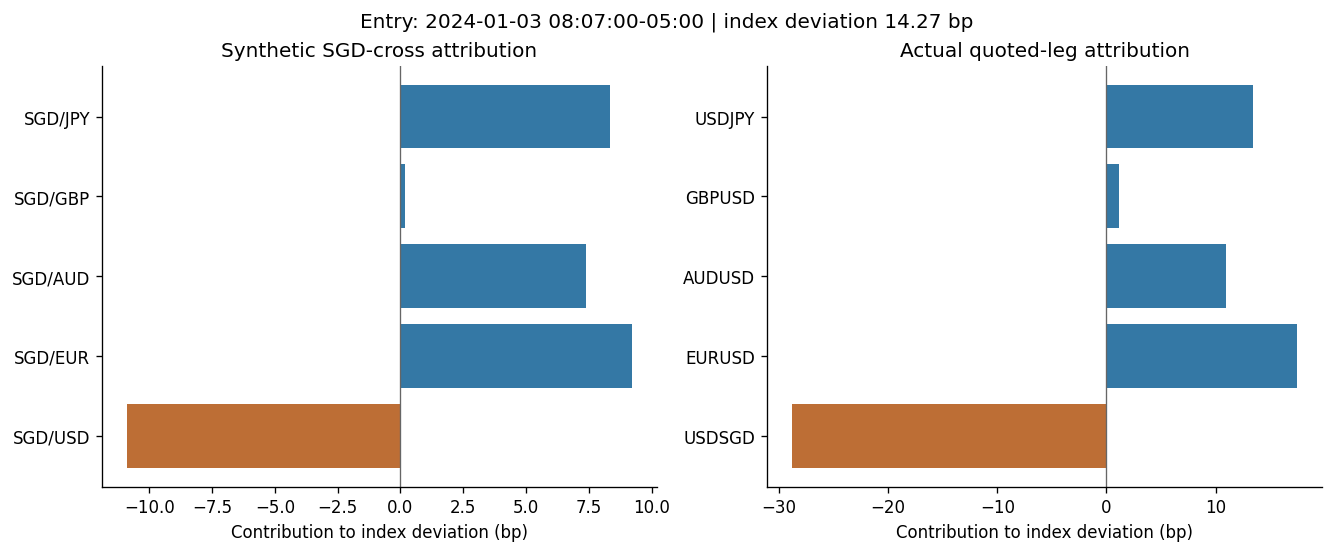

In [2]:
example = pd.read_csv(results/'example_attribution.csv')
drivers = pd.read_csv(results/'quoted_leg_attribution.csv')
drivers['timestamp'] = pd.to_datetime(drivers.timestamp,utc=True)
row = drivers.loc[drivers.timestamp == pd.Timestamp('2024-01-03 08:07:00-05:00').tz_convert('UTC')].iloc[0]
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
axes[0].barh('SGD/'+example.currency,example.weighted_deviation_bp,
             color=np.where(example.aligned,'#3478a5','#bd6e35'))
pairs = ['USDSGD','EURUSD','AUDUSD','GBPUSD','USDJPY']
values = row[pairs].astype(float)*1e4
axes[1].barh(pairs,values,color=np.where(values*row.index_deviation > 0,'#3478a5','#bd6e35'))
for ax,title in zip(axes,['Synthetic SGD-cross attribution','Actual quoted-leg attribution']):
    ax.axvline(0,color='0.4',lw=.8)
    ax.set(title=title,xlabel='Contribution to index deviation (bp)')
fig.suptitle('Entry: 2024-01-03 08:07:00-05:00 | index deviation 14.27 bp')
fig.savefig(results/'attribution_example.png',dpi=160)
plt.show()


## Subset rules and sizing

Aligned keeps all same-sign contributors; top1/top2 keep the largest contributions; coverage80 covers 80% of positive contributions; cost_top2 applies a cross-specific spread hurdle and ranks contribution per cost. Retained weights lower SGD exposure; normalized weights keep SGD exposure fixed; risk matching rescales normalized weights using prior covariance.

The following grid uses the same 24h equilibrium / 1.5z index events. Each Sharpe cell also shows the average estimated risk relative to the full portfolio at entry. Risk-matched portfolios need not realize exactly the same future volatility.

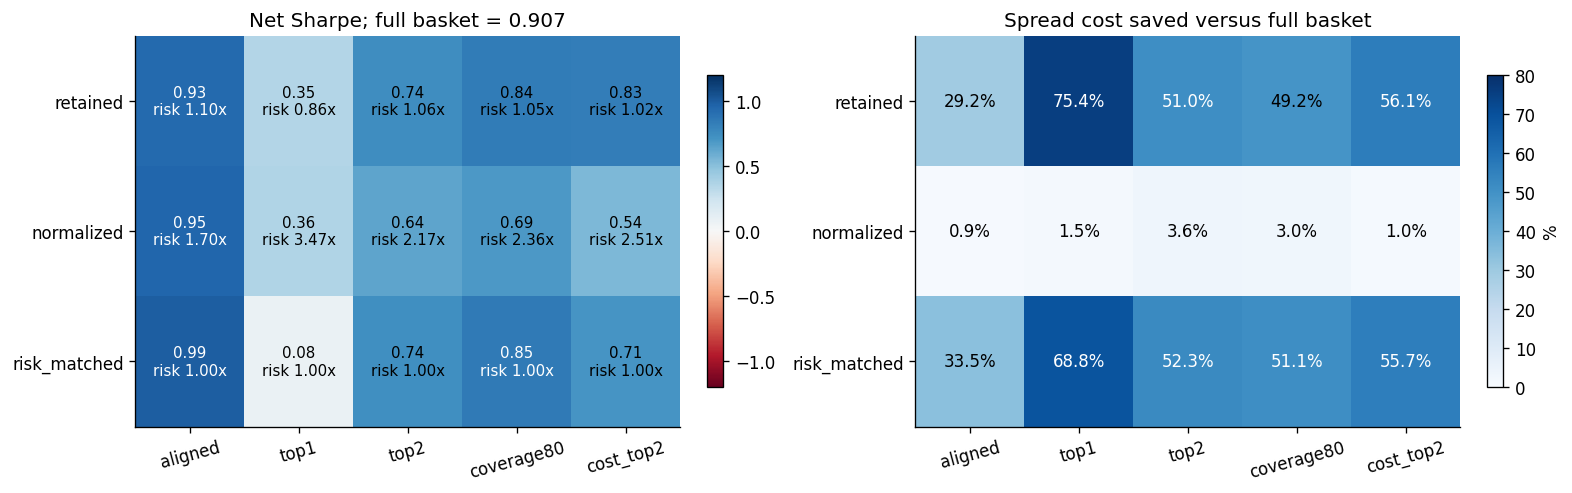

,rule,sizing,sharpe,cost_ratio,mean_selected_count,mean_exante_risk_ratio,annual_vol
policy,,,,,,,
equilibrium_24h_z1.5__aligned__retained,aligned,retained,0.930,0.708,3.423,1.104,0.032
equilibrium_24h_z1.5__aligned__normalized,aligned,normalized,0.948,0.991,3.423,1.700,0.050
equilibrium_24h_z1.5__aligned__risk_matched,aligned,risk_matched,0.991,0.665,3.423,1.000,0.029
equilibrium_24h_z1.5__top1__retained,top1,retained,0.351,0.246,1.000,0.859,0.023
equilibrium_24h_z1.5__top1__normalized,top1,normalized,0.360,0.985,1.000,3.466,0.099
equilibrium_24h_z1.5__top1__risk_matched,top1,risk_matched,0.076,0.312,1.000,1.000,0.027
equilibrium_24h_z1.5__top2__retained,top2,retained,0.744,0.490,1.979,1.055,0.029
equilibrium_24h_z1.5__top2__normalized,top2,normalized,0.637,0.964,1.979,2.166,0.058
equilibrium_24h_z1.5__top2__risk_matched,top2,risk_matched,0.737,0.477,1.979,1.000,0.027


In [3]:
part = final.query("trigger == 'equilibrium_24h_z1.5' and rule != 'full'")
rules = ['aligned','top1','top2','coverage80','cost_top2']
sizes = ['retained','normalized','risk_matched']
values = part.pivot(index='sizing',columns='rule',values='sharpe').reindex(index=sizes,columns=rules)
risk = part.pivot(index='sizing',columns='rule',values='mean_exante_risk_ratio').reindex(index=sizes,columns=rules)
saving = 100*(1-part.pivot(index='sizing',columns='rule',values='cost_ratio').reindex(index=sizes,columns=rules))
fig, axes = plt.subplots(1,2,figsize=(13,4),layout='constrained')
im = axes[0].imshow(values,cmap='RdBu',vmin=-1.2,vmax=1.2,aspect='auto')
im2 = axes[1].imshow(saving,cmap='Blues',vmin=0,vmax=80,aspect='auto')
for i in range(3):
    for j in range(5):
        axes[0].text(j,i,f'{values.iloc[i,j]:.2f}\nrisk {risk.iloc[i,j]:.2f}x',ha='center',va='center',fontsize=9,
                     color='white' if abs(values.iloc[i,j])>.85 else 'black')
        axes[1].text(j,i,f'{saving.iloc[i,j]:.1f}%',ha='center',va='center',fontsize=10,
                     color='white' if saving.iloc[i,j]>50 else 'black')
for ax in axes:
    ax.set_xticks(range(5),rules,rotation=15)
    ax.set_yticks(range(3),sizes)
axes[0].set_title('Net Sharpe; full basket = 0.907')
axes[1].set_title('Spread cost saved versus full basket')
fig.colorbar(im,ax=axes[0],shrink=.8)
fig.colorbar(im2,ax=axes[1],shrink=.8,label='%')
fig.savefig(results/'subset_risk_cost_grid.png',dpi=160)
plt.show()
display(part[['rule','sizing','sharpe','cost_ratio','mean_selected_count','mean_exante_risk_ratio','annual_vol']].round(3))


## Component outcomes at the original index exit

These diagnostic returns are per unit of synthetic cross, equally weighted across observations, including each cross's two-leg spread. Multiple components share the same index trade and are not independent observations. Future outcomes are never used to choose a subset.

In [4]:
display(pd.read_csv(results/'aligned_component_outcomes.csv').round(3))
display(pd.read_csv(results/'rank_component_outcomes.csv').round(3))


,aligned,cross_observations,gross_bp,net_bp,gross_win_fraction
0,False,298,2.268,-0.922,0.604
1,True,647,6.280,3.073,0.655


,contribution_rank,cross_observations,gross_bp,net_bp
0,1,189,4.721,1.860
1,2,189,7.743,4.718
2,3,189,5.515,2.018
3,4,189,5.423,2.125
4,5,189,1.673,-1.654


## Stability and development-only selection

The main comparison preserves the 1.5z trigger selected in the previous study. Its modest recent Sharpe gain does not exceed the full basket in every earlier period. The separate development-only subset shortlist requires positive performance and improvement over its parent in all three development/validation periods, plus minimum activity.

Development-only subset shortlist: ['equilibrium_24h_z2__coverage80__normalized', 'equilibrium_24h_z2__top2__normalized', 'equilibrium_24h_z2__aligned__normalized']


period,development,recent_development,validation,2024,2025,evaluation,all_2017_2025
policy,,,,,,,
equilibrium_24h_z1.5__full__retained,1.454,1.259,2.045,1.146,0.677,0.907,1.397
equilibrium_24h_z1.5__aligned__retained,1.392,1.396,2.388,0.585,1.352,0.930,1.378
equilibrium_24h_z1.5__aligned__normalized,1.442,1.743,2.375,0.675,1.307,0.948,1.419
equilibrium_24h_z1.5__aligned__risk_matched,1.368,1.359,2.324,0.464,1.514,0.991,1.369
equilibrium_24h_z1.5__top1__risk_matched,0.814,1.455,0.449,-0.651,0.803,0.076,0.631
equilibrium_24h_z1.5__top2__risk_matched,1.178,1.583,1.495,0.427,1.021,0.737,1.111
equilibrium_24h_z1.5__coverage80__risk_matched,1.263,1.369,2.040,-0.171,1.956,0.850,1.248
equilibrium_24h_z1.5__cost_top2__risk_matched,1.048,1.338,1.323,-0.342,1.787,0.705,1.003


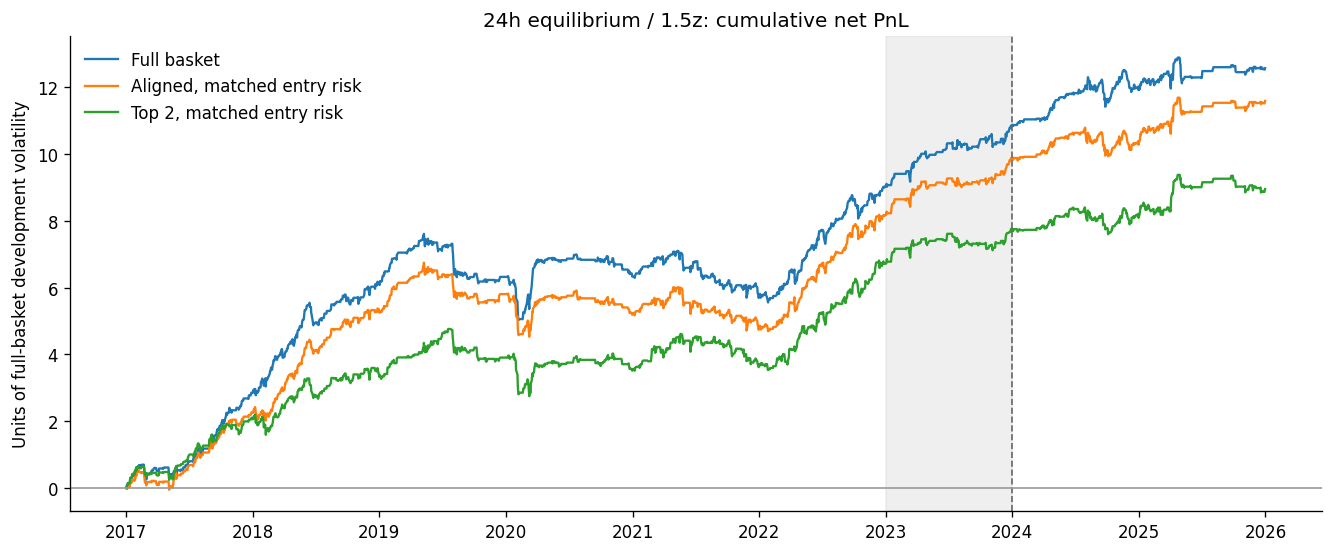

period,development,recent_development,validation,2024,2025,evaluation,all_2017_2025
policy,,,,,,,
equilibrium_24h_z2__coverage80__normalized,1.255,1.709,2.179,0.909,-0.016,0.581,1.145
equilibrium_24h_z2__top2__normalized,1.213,2.000,1.334,0.727,-0.055,0.414,1.040
equilibrium_24h_z2__aligned__normalized,1.162,2.178,2.214,0.394,0.491,0.424,1.099


,policy,development,recent_development,validation,score,improvement_score,validation_completed_trades,validation_active_days,eligible
0,equilibrium_24h_z2__coverage80__normalized,1.255,1.709,2.179,1.255,0.331,23,44,True
1,equilibrium_24h_z2__top2__normalized,1.213,2.000,1.334,1.213,0.289,23,44,True
2,equilibrium_24h_z2__aligned__normalized,1.162,2.178,2.214,1.162,0.238,23,44,True
3,equilibrium_24h_z2__coverage80__retained,1.122,1.711,2.338,1.122,0.198,23,44,True
4,equilibrium_24h_z2__coverage80__risk_matched,1.121,1.720,2.211,1.121,0.197,23,44,True
5,equilibrium_24h_z2__top2__risk_matched,1.071,1.911,1.341,1.071,0.147,23,44,True
6,equilibrium_24h_z2__top2__retained,1.060,1.866,1.247,1.060,0.136,23,44,True
7,return_24h_z2__coverage80__retained,1.021,1.563,2.048,1.021,0.121,36,56,True
8,equilibrium_72h_z1.5__aligned__risk_matched,0.819,0.281,0.956,0.281,0.116,22,87,True
9,equilibrium_72h_z1.5__aligned__retained,0.815,0.291,1.056,0.291,0.111,22,87,True


In [5]:
names = ['equilibrium_24h_z1.5__full__retained', 'equilibrium_24h_z1.5__aligned__retained', 'equilibrium_24h_z1.5__aligned__normalized', 'equilibrium_24h_z1.5__aligned__risk_matched', 'equilibrium_24h_z1.5__top1__risk_matched', 'equilibrium_24h_z1.5__top2__risk_matched', 'equilibrium_24h_z1.5__coverage80__risk_matched', 'equilibrium_24h_z1.5__cost_top2__risk_matched']
display(scores.loc[names,['development', 'recent_development', 'validation', '2024', '2025', 'evaluation', 'all_2017_2025']].round(3))
fig, ax = plt.subplots(figsize=(11,4.5),layout='constrained')
parent = pd.read_csv(results/'daily_equilibrium_24h_z1.5__full__retained_fill0.csv.gz',index_col=0,parse_dates=True).net
scale = parent.loc['2017':'2022'].std()*np.sqrt(252)
for name,label in [('equilibrium_24h_z1.5__full__retained','Full basket'),('equilibrium_24h_z1.5__aligned__risk_matched','Aligned, matched entry risk'),
                   ('equilibrium_24h_z1.5__top2__risk_matched','Top 2, matched entry risk')]:
    daily = pd.read_csv(results/f'daily_{name}_fill0.csv.gz',index_col=0,parse_dates=True).net
    ax.plot(daily.loc['2017':].cumsum()/scale,label=label,lw=1.4)
ax.axvspan(pd.Timestamp('2023-01-01'),pd.Timestamp('2024-01-01'),color='0.8',alpha=.3)
ax.axvline(pd.Timestamp('2024-01-01'),color='0.4',ls='--',lw=1)
ax.axhline(0,color='0.6',lw=1)
ax.set(title='24h equilibrium / 1.5z: cumulative net PnL',ylabel='Units of full-basket development volatility')
ax.legend(frameon=False)
fig.savefig(results/'subset_cumulative_pnl.png',dpi=160)
plt.show()
selected = json.loads((results/'frozen_selection.json').read_text())['selected']
print('Development-only subset shortlist:',selected)
display(scores.loc[selected,['development', 'recent_development', 'validation', '2024', '2025', 'evaluation', 'all_2017_2025']].round(3))
display(pd.read_csv(results/'leaderboard.csv').head(16).round(3))


## Execution stress and paired uncertainty

Intervals for Sharpe improvement use the same 20-day-block resamples for each subset and its parent, with 2,000 draws. They do not adjust for searching many variants. One quote of delay may exceed one elapsed minute across an outage. No financing is included.

In [6]:
display(comparison[(comparison.period == 'evaluation') & comparison.policy.isin(names)].pivot(index='policy',columns='fill_delay_minutes',values='sharpe').round(3))
stress = pd.read_csv(results/'stress.csv')
display(stress[(stress.fill_delay_minutes == 0) & stress.policy.isin(names)].pivot(index='policy',columns='scenario',values='sharpe').round(3))
display(pd.read_csv(results/'bootstrap.csv').set_index('policy').loc[names,['low','high','delta_low','delta_median','delta_high']].round(3))
display(final.pivot(index=['trigger','rule'],columns='sizing',values='sharpe').round(3))


fill_delay_minutes,0,1
policy,,
equilibrium_24h_z1.5__aligned__normalized,0.948,0.539
equilibrium_24h_z1.5__aligned__retained,0.930,0.526
equilibrium_24h_z1.5__aligned__risk_matched,0.991,0.530
equilibrium_24h_z1.5__cost_top2__risk_matched,0.705,0.379
equilibrium_24h_z1.5__coverage80__risk_matched,0.850,0.456
equilibrium_24h_z1.5__full__retained,0.907,0.321
equilibrium_24h_z1.5__top1__risk_matched,0.076,-0.200
equilibrium_24h_z1.5__top2__risk_matched,0.737,0.365


scenario,base,extra_0.25bp_per_leg,spread_x2
policy,,,
equilibrium_24h_z1.5__aligned__normalized,0.948,0.570,-0.371
equilibrium_24h_z1.5__aligned__retained,0.930,0.514,-0.528
equilibrium_24h_z1.5__aligned__risk_matched,0.991,0.570,-0.519
equilibrium_24h_z1.5__cost_top2__risk_matched,0.705,0.406,-0.380
equilibrium_24h_z1.5__coverage80__risk_matched,0.850,0.515,-0.358
equilibrium_24h_z1.5__full__retained,0.907,0.321,-1.162
equilibrium_24h_z1.5__top1__risk_matched,0.076,-0.147,-0.711
equilibrium_24h_z1.5__top2__risk_matched,0.737,0.411,-0.425


,low,high,delta_low,delta_median,delta_high
policy,,,,,
equilibrium_24h_z1.5__full__retained,-0.393,2.224,0.000,0.000,0.000
equilibrium_24h_z1.5__aligned__retained,-0.402,2.252,-0.803,0.033,0.803
equilibrium_24h_z1.5__aligned__normalized,-0.353,2.207,-0.819,0.031,0.820
equilibrium_24h_z1.5__aligned__risk_matched,-0.384,2.257,-0.750,0.074,0.809
equilibrium_24h_z1.5__top1__risk_matched,-1.261,1.321,-2.248,-0.843,0.490
equilibrium_24h_z1.5__top2__risk_matched,-0.761,2.139,-1.391,-0.225,0.907
equilibrium_24h_z1.5__coverage80__risk_matched,-0.789,2.418,-1.270,-0.112,1.082
equilibrium_24h_z1.5__cost_top2__risk_matched,-1.136,2.375,-1.453,-0.256,1.064


sizing                           normalized  retained  risk_matched
trigger              rule                                          
equilibrium_24h_z1.5 aligned          0.948     0.930         0.991
                     cost_top2        0.539     0.831         0.705
                     coverage80       0.690     0.842         0.850
                     full               NaN     0.907           NaN
                     top1             0.360     0.351         0.076
                     top2             0.637     0.744         0.737
equilibrium_24h_z2   aligned          0.424     0.238         0.267
                     cost_top2        0.547     0.197         0.121
                     coverage80       0.581    -0.036         0.014
                     full               NaN     0.246           NaN
                     top1             0.418     0.161        -0.094
                     top2             0.414     0.205         0.228
equilibrium_72h_z1.5 aligned          0.555     0.266         0.161
                     cost_top2        0.368     0.101        -0.042
                     coverage80       0.800     0.622         0.451
                     full               NaN     0.785           NaN
                     top1             0.834     0.787         0.634
                     top2             0.548     0.319         0.125
return_24h_z2        aligned          0.540     0.050        -0.119
                     cost_top2       -0.331    -0.341        -0.538
                     coverage80       0.257    -0.189        -0.475
                     full               NaN    -0.228           NaN
                     top1             0.108    -0.190        -0.444
                     top2            -0.180    -0.205        -0.346

## Reproduce and inspect a particular trade

```sh
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_subset.py
```

Definitions are in `sgd_neer_subset.py`: `component_deviations()` implements attribution, `select_crosses()` chooses a subset, `subset_targets()` freezes its entry weights and sizing, and `PairAccountant` calculates actual netted pair costs. `run_sgd_neer_subset.py` declares the triggers and rules.

For each policy, `decisions_*.csv.gz` contains timestamps, cross deviations, contributions, selected flags, exposures and estimated risk ratios. `trades_*.csv.gz` contains actual fill times, before/after positions and cost per quoted pair. `daily_*.csv.gz` records full daily PnL. All full controls reproduce previous results. The 47 related tests passed.

The input uses the existing common five-pair one-minute cache, with missing market minutes retained and no extra filling. The exporter may already have filled stale quotes for up to ten minutes. 2023 coverage is incomplete. These are exploratory results from previously inspected evaluation dates.